In [ ]:
# load libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as ticker

In [4]:
# load the data
df = pd.read_csv('final_dataset.csv')

In [ ]:
# shape of the dataset
df.shape


(40301, 79)

In [4]:
# check columns
df.columns

Index(['blurb', 'category_name', 'category_parent_name', 'country',
       'created_at', 'creator_has_admin_message_badge',
       'creator_ppo_has_action', 'creator_backing_action_count', 'currency',
       'deadline', 'disable_communication', 'goal', 'id', 'is_disliked',
       'is_liked', 'is_starrable', 'launched_at', 'location_name',
       'location_country', 'location_state', 'location_type', 'name',
       'photo_1536x864', 'prelaunch_activated', 'profile_id',
       'profile_project_id', 'profile_show_feature_image',
       'profile_should_show_feature_image_section',
       'profile_feature_image_attributes_image_urls_default',
       'profile_feature_image_attributes_image_urls_baseball_card', 'slug',
       'source_url', 'staff_pick', 'static_usd_rate', 'urls_web_project',
       'urls_web_rewards', 'video', 'story_html', 'risks_html', 'rewards_html',
       'pledged', 'backers_count', 'usd_pledged', 'converted_pledged_amount',
       'profile_state', 'profile_state_changed

In [ ]:
# number of projects
print("Total number of projects:", len(df))
print(df['state'].value_counts())

Total number of projects: 40301
state
successful    20556
failed        19745
Name: count, dtype: int64


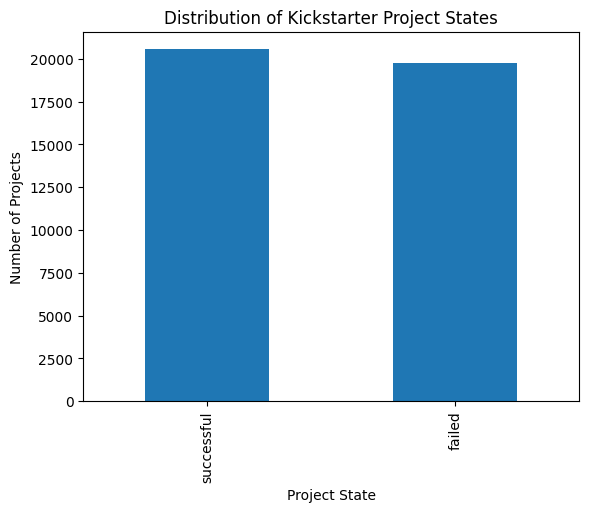

In [ ]:
# histogram of the 'state' column
df['state'].value_counts().plot(kind='bar')
plt.xlabel('Project State')
plt.ylabel('Number of Projects')
plt.title('Distribution of Kickstarter Project States')
plt.show()

In [8]:
# check data types
print(df.dtypes)

blurb                                                            str
category_name                                                    str
category_parent_name                                             str
country                                                          str
created_at                                                       str
creator_has_admin_message_badge                                 bool
creator_ppo_has_action                                          bool
creator_backing_action_count                                 float64
currency                                                         str
deadline                                                         str
disable_communication                                           bool
goal                                                         float64
id                                                             int64
is_disliked                                                     bool
is_liked                          

In [ ]:
# check has_restricted_shipping
print(df['has_restricted_shipping'].value_counts())

has_restricted_shipping
0    24911
1    15390
Name: count, dtype: int64


In [ ]:
# define text columns and convert to string type
text_cols = [
    "blurb", "name", "story_html", "risks_html", "rewards_html", "slug", "rewards_html_text", "risks_html_text", 'story_html_text'
]

df[text_cols] = df[text_cols].astype("string")

In [ ]:
# define categorical columns and convert to category type
categorical_cols = [
    "category_name", 
    "category_parent_name", 
    "country", 
    "currency", 
    "location_name", 
    "location_state", 
    "location_country", 
    "location_type"
]
for col in categorical_cols:
    df[col] = df[col].astype("category")

In [ ]:
# define boolean columns and convert to bool type
bool_cols = [
    'creator_has_admin_message_badge',
    'creator_ppo_has_action',
    'disable_communication',
    'is_disliked',
    'is_liked',
    'is_starrable',
    'prelaunch_activated',
    'profile_show_feature_image',
    'profile_should_show_feature_image_section',
    'video',
    'staff_pick',
    'spotlight',
    'is_english_project',
    'profile_state',
    'has_reward_images',
    'has_restricted_shipping'
    ]

for col in bool_cols:
    if col in df.columns:
        df[col] = df[col].astype(bool)


In [ ]:
# define URL columns and convert to string type
urls_cols = [
    "photo_1536x864",
    "profile_feature_image_attributes_image_urls_default",
    "profile_feature_image_attributes_image_urls_baseball_card",
    "source_url",
    "urls_web_project",
    "urls_web_rewards"
]
for col in urls_cols:
    if col in df.columns:
        df[col] = df[col].astype("string")

In [ ]:
# Convert to datetime
date_cols = ['created_at', 'launched_at', 'deadline', 'profile_state_changed_at', 'state_changed_at']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Check
print(df[date_cols].dtypes)

print(df[['created_at', 'launched_at', 'deadline', 'profile_state_changed_at', 'state_changed_at']].head())

created_at                  datetime64[us]
launched_at                 datetime64[us]
deadline                    datetime64[us]
profile_state_changed_at    datetime64[us]
state_changed_at            datetime64[us]
dtype: object
           created_at         launched_at            deadline  \
0 2016-01-19 03:48:47 2016-02-26 12:38:27 2016-04-01 11:38:27   
1 2023-10-07 20:25:28 2024-07-02 19:11:53 2024-08-03 03:59:00   
2 2022-10-26 11:42:19 2022-11-07 15:04:01 2022-12-02 15:04:01   
3 2018-09-20 02:23:08 2019-09-25 22:47:29 2019-10-25 22:47:29   
4 2025-01-18 18:34:56 2025-03-04 13:55:15 2025-03-29 03:59:00   

  profile_state_changed_at    state_changed_at  
0      2016-01-19 03:48:47 2016-04-01 11:38:28  
1      2024-08-03 13:31:37 2024-08-03 03:59:00  
2      2022-10-26 11:42:19 2022-12-02 15:04:01  
3      2018-09-20 02:23:08 2019-10-25 22:47:29  
4      2025-05-11 17:51:28 2025-03-29 03:59:04  


In [15]:
# check data types
print(df.dtypes)

blurb                                                                string
category_name                                                      category
category_parent_name                                               category
country                                                            category
created_at                                                   datetime64[us]
creator_has_admin_message_badge                                        bool
creator_ppo_has_action                                                 bool
creator_backing_action_count                                        float64
currency                                                           category
deadline                                                     datetime64[us]
disable_communication                                                  bool
goal                                                                float64
id                                                                    int64
is_disliked 

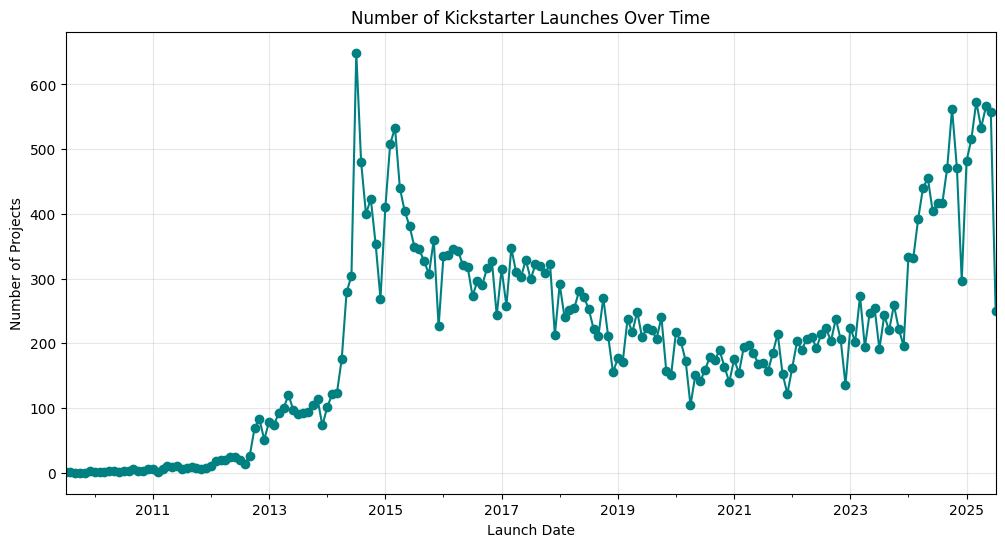

In [ ]:
# time series analysis of launched_at
monthly_launches = df.set_index('launched_at').resample('ME').size()

plt.figure(figsize=(12, 6))
monthly_launches.plot(kind='line', marker='o', color='teal')
plt.title('Number of Kickstarter Launches Over Time')
plt.ylabel('Number of Projects')
plt.xlabel('Launch Date')
plt.grid(True, alpha=0.3)
plt.show()

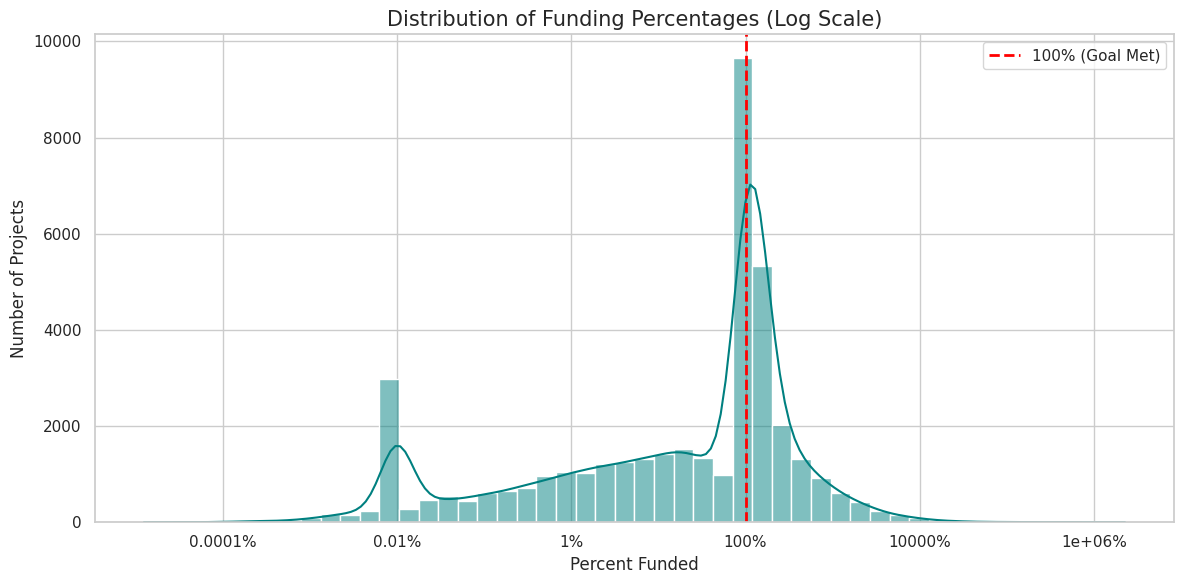

In [ ]:
# place 0 with a tiny value for the log scale
plot_df = df.copy()
plot_df['percent_funded_clean'] = plot_df['percent_funded'].replace(0, 0.01)

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# distribution plot (Histogram + KDE)
sns.histplot(data=plot_df, x='percent_funded_clean', bins=50, kde=True, 
             color='teal', log_scale=True)

# vertical line at 100%
plt.axvline(100, color='red', linestyle='--', linewidth=2, label='100% (Goal Met)')

# Format the X-axis with percentages
def pct_formatter(x, pos):
    return f'{x:g}%'
plt.gca().xaxis.set_major_formatter(FuncFormatter(pct_formatter))

# Labels and Title
plt.title('Distribution of Funding Percentages (Log Scale)', fontsize=15)
plt.xlabel('Percent Funded', fontsize=12)
plt.ylabel('Number of Projects', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

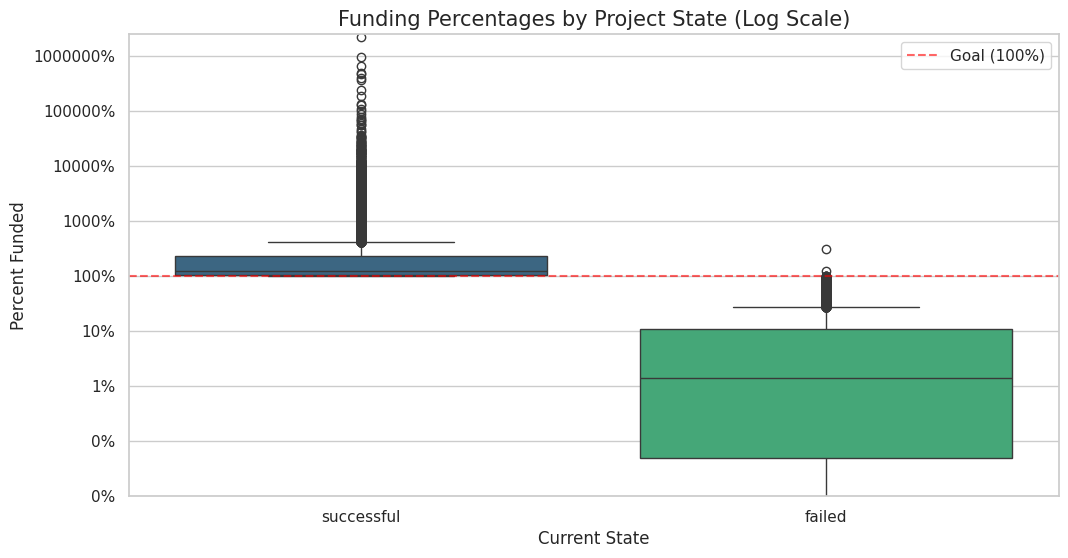

In [ ]:
plt.figure(figsize=(12, 6))

# Safety check for log scale
plot_df = df.copy()
plot_df['percent_funded_log'] = plot_df['percent_funded'].replace(0, 0.01)

sns.boxplot(x='state', y='percent_funded_log', data=plot_df, palette='viridis', hue ='state', legend=False)

# Apply log scale
plt.yscale('log')

# Format y-axis as percentages
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.0f}%'))

plt.title('Funding Percentages by Project State (Log Scale)', fontsize=15)
plt.xlabel('Current State', fontsize=12)
plt.ylabel('Percent Funded', fontsize=12)

# Highlight 100% funding
plt.axhline(y=100, color='red', linestyle='--', alpha=0.6, label='Goal (100%)')
plt.ylim(0.01, plot_df['percent_funded_log'].max()*1.1)
plt.legend()

plt.show()

In [19]:
# show projects with percent_funded >= 100 that has state 'failed'
failed_high_funding = df[(df['state'] == 'failed') & (df['percent_funded'] >= 100)]
print("Projects with percent_funded >= 100 that have state 'failed':")
print(failed_high_funding[['name', 'percent_funded', 'state', 'urls_web_project']])

Projects with percent_funded >= 100 that have state 'failed':
                               name  percent_funded   state  \
6692                      "Balance"      100.087000  failed   
18953         Phelps Ceramic Studio      123.647059  failed   
26376  Off Grid Mobile Mesh Network      310.200000  failed   

                                        urls_web_project  
6692   https://www.kickstarter.com/projects/112202108...  
18953  https://www.kickstarter.com/projects/dustinphe...  
26376  https://www.kickstarter.com/projects/824280148...  


In [51]:
# change state of projects with percent_funded >= 100 that have state 'failed' to 'successful'
df.loc[(df['state'] == 'failed') & (df['percent_funded'] >= 100), 'state'] = 'successful'
print("Updated state of projects with percent_funded >= 100 that were previously 'failed' to 'successful'.")
# change success of projects with percent_funded >= 100 that have success = 0 to 1
df.loc[(df['percent_funded'] >= 100) & (df['success'] == 0), 'success'] = 1
print("Updated success of projects with percent_funded >= 100 that were previously 0 to 1.")

Updated state of projects with percent_funded >= 100 that were previously 'failed' to 'successful'.
Updated success of projects with percent_funded >= 100 that were previously 0 to 1.


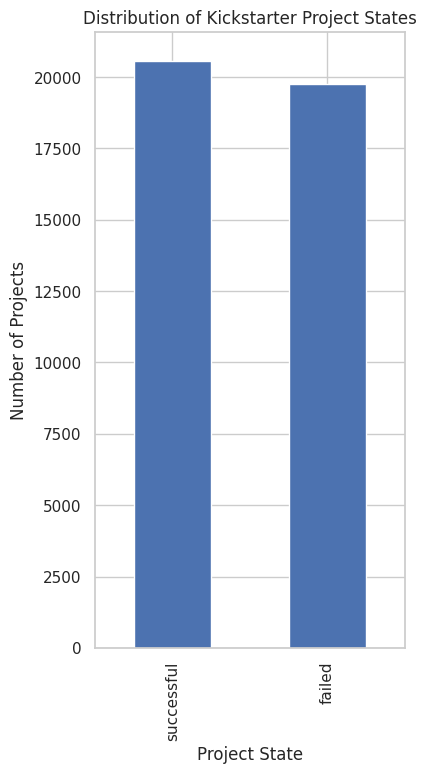

In [ ]:
# plot a histogram of the 'state' column
plt.figure(figsize=(4,8))
df['state'].value_counts().plot(kind='bar')
plt.xlabel('Project State')
plt.ylabel('Number of Projects')
plt.title('Distribution of Kickstarter Project States')
plt.show()

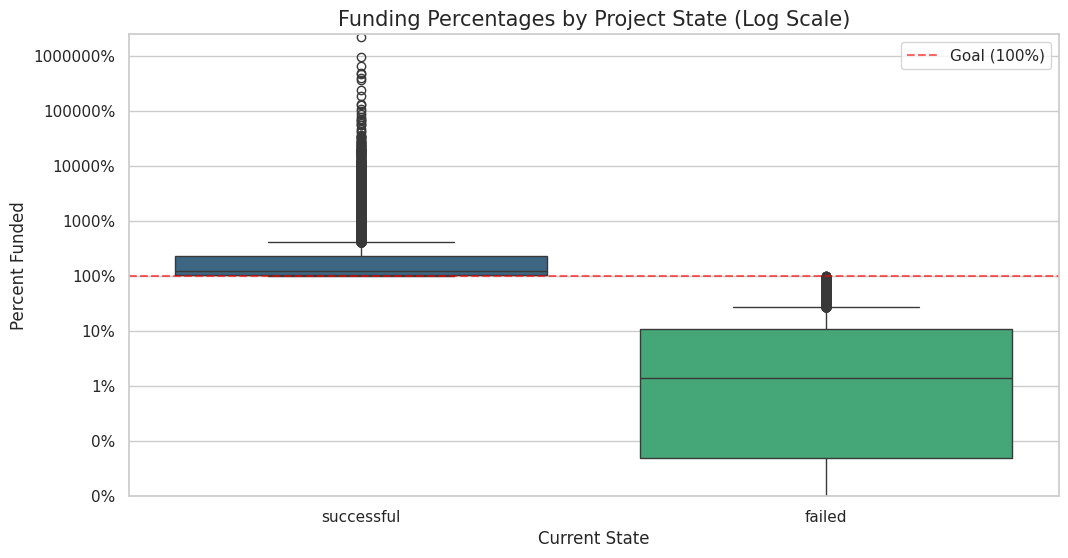

In [57]:
plt.figure(figsize=(12, 6))

# Safety check for log scale
plot_df = df.copy()
plot_df['percent_funded_log'] = plot_df['percent_funded'].replace(0, 0.01)

sns.boxplot(x='state', y='percent_funded_log', data=plot_df, palette='viridis', hue ='state', legend=False)

# Apply log scale
plt.yscale('log')

# Format y-axis as percentages
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.0f}%'))

plt.title('Funding Percentages by Project State (Log Scale)', fontsize=15)
plt.xlabel('Current State', fontsize=12)
plt.ylabel('Percent Funded', fontsize=12)

# Highlight 100% funding
plt.axhline(y=100, color='red', linestyle='--', alpha=0.6, label='Goal (100%)')
plt.ylim(0.01, plot_df['percent_funded_log'].max()*1.1)
plt.legend()

plt.show()

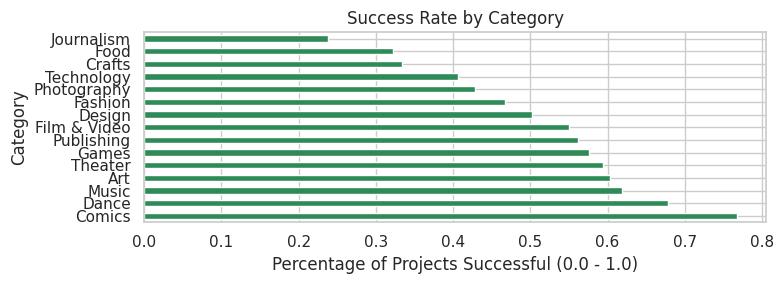

In [58]:
# Calculate success rate per category
category_success = df.groupby('category_parent_name')['state'].value_counts(normalize=True).unstack().fillna(0)
category_success = category_success['successful'].sort_values(ascending=False)

# Plot
plt.figure(figsize=(8, 3))
category_success.plot(kind='barh', color='seagreen')
plt.title('Success Rate by Category')
plt.xlabel('Percentage of Projects Successful (0.0 - 1.0)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

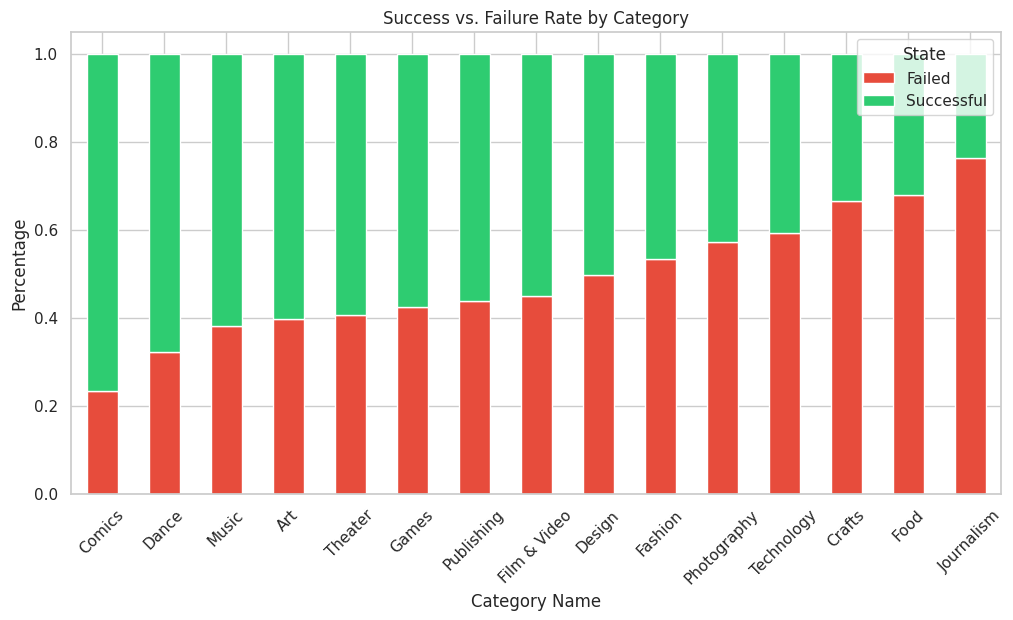

In [24]:
# Calculate success rates per category
category_stats = df.groupby('category_parent_name')['state'].value_counts(normalize=True).unstack().fillna(0)
category_stats = category_stats.sort_values(by='successful', ascending=False)

# Plotting
category_stats.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#e74c3c', '#2ecc71'])
plt.title('Success vs. Failure Rate by Category')
plt.ylabel('Percentage')
plt.xlabel('Category Name')
plt.legend(title='State', labels=['Failed', 'Successful'], loc='upper right')
plt.xticks(rotation=45)
plt.show()

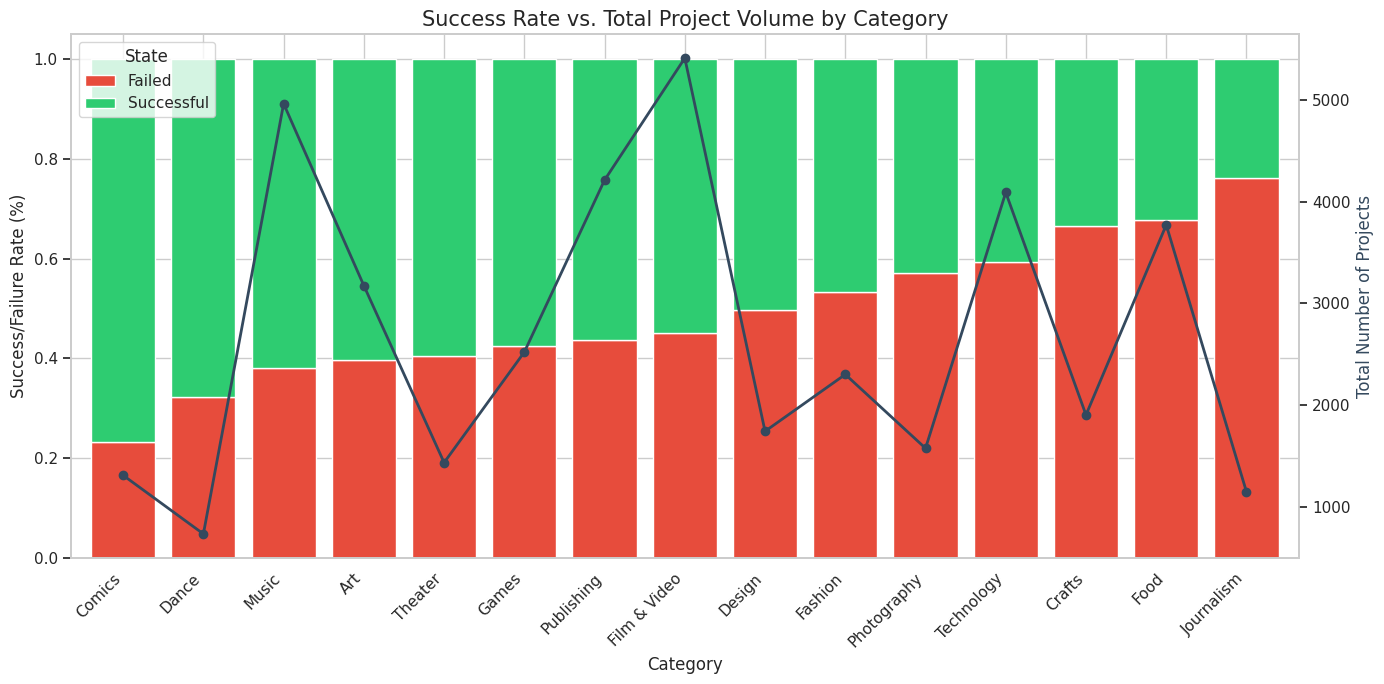

In [ ]:
# normalize rates for the bars
category_stats = df.groupby('category_parent_name')['state'].value_counts(normalize=True).unstack().fillna(0)
category_stats = category_stats.sort_values(by='successful', ascending=False)

# Get raw counts for the line overlay
category_counts = df['category_parent_name'].value_counts().reindex(category_stats.index)

# Stacked Bars
fig, ax1 = plt.subplots(figsize=(14, 7))

category_stats.plot(kind='bar', stacked=True, ax=ax1, color=['#e74c3c', '#2ecc71'], width=0.8)
ax1.set_ylabel('Success/Failure Rate (%)', fontsize=12)
ax1.set_xlabel('Category', fontsize=12)
ax1.set_title('Success Rate vs. Total Project Volume by Category', fontsize=15)
ax1.legend(title='State', labels=['Failed', 'Successful'], loc='upper left')

# Secondary Y-Axis for Volume
ax2 = ax1.twinx() 
ax2.plot(range(len(category_counts)), category_counts.values, color='#34495e', marker='o', linewidth=2, label='Total Projects')
ax2.set_ylabel('Total Number of Projects', fontsize=12, color='#34495e')
ax2.grid(False)

# Format
ax1.set_xticklabels(category_stats.index, rotation=45, ha='right')
plt.tight_layout()
plt.show()

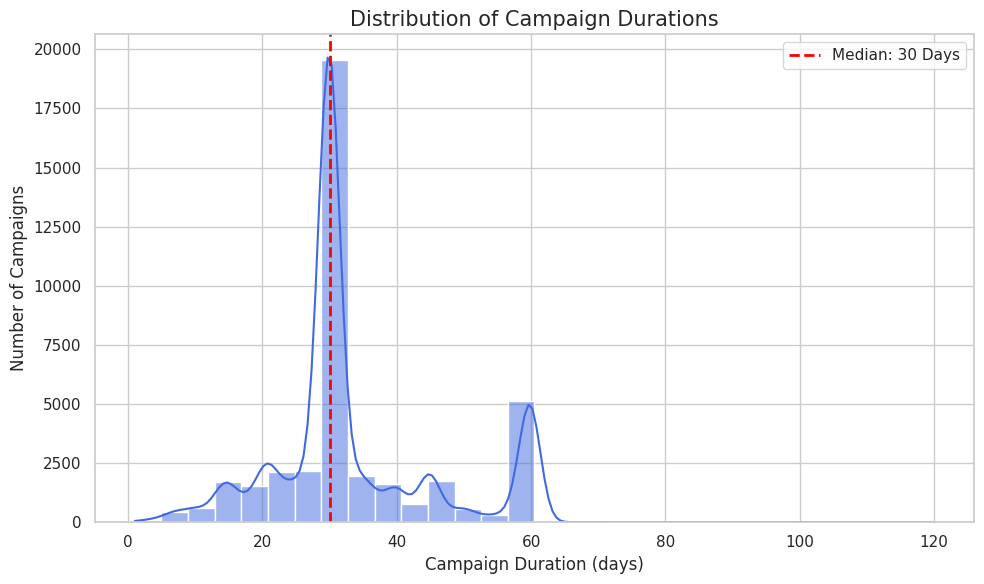

In [ ]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# distribution plot (Histogram + KDE)
sns.histplot(data=df, x='campaign_duration_days', bins=30, kde=True, color='royalblue')

# Add a vertical line for the median duration
median_val = df['campaign_duration_days'].median()
plt.axvline(median_val, color='red', linestyle='--', linewidth=2, label=f'Median: {median_val:.0f} Days')

plt.title('Distribution of Campaign Durations', fontsize=15)
plt.xlabel('Campaign Duration (days)', fontsize=12)
plt.ylabel('Number of Campaigns', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# campaign duration descriptive statistics
print("Campaign Duration (days) - Descriptive Statistics:")
print(df['campaign_duration_days'].describe())


Campaign Duration (days) - Descriptive Statistics:
count    40301.000000
mean        33.479020
std         12.715575
min          1.000000
25%         29.000000
50%         30.000000
75%         37.000000
max        120.000000
Name: campaign_duration_days, dtype: float64


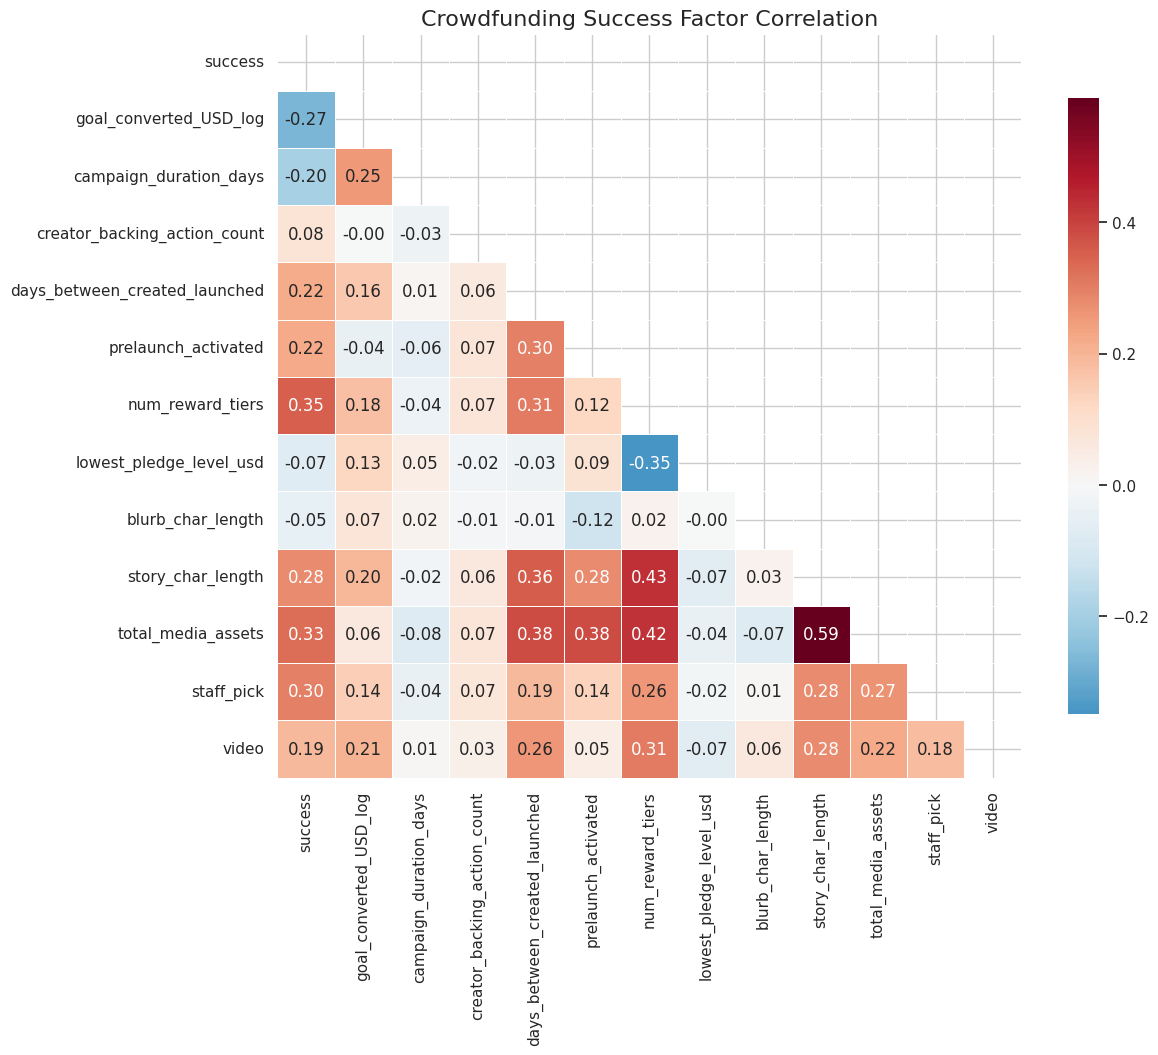

In [ ]:
# impactful numerical and boolean features
features_for_corr = [
    'success', 'goal_converted_USD_log', 'campaign_duration_days', 
    'creator_backing_action_count', 'days_between_created_launched', 'prelaunch_activated',
    'num_reward_tiers', 'lowest_pledge_level_usd',
    'blurb_char_length', 'story_char_length', 'total_media_assets',
    'staff_pick', 'video'
]

# Create a sub-dataframe and convert booleans to 0/1
corr_df = df[features_for_corr].copy()
corr_df['prelaunch_activated'] = corr_df['prelaunch_activated'].astype(int)
corr_df['staff_pick'] = corr_df['staff_pick'].astype(int)
corr_df['video'] = corr_df['video'].astype(int)

# Calculate Correlation
corr_matrix = corr_df.corr(method='spearman')

# Plot
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='RdBu_r', center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Crowdfunding Success Factor Correlation', fontsize=16)
plt.show()

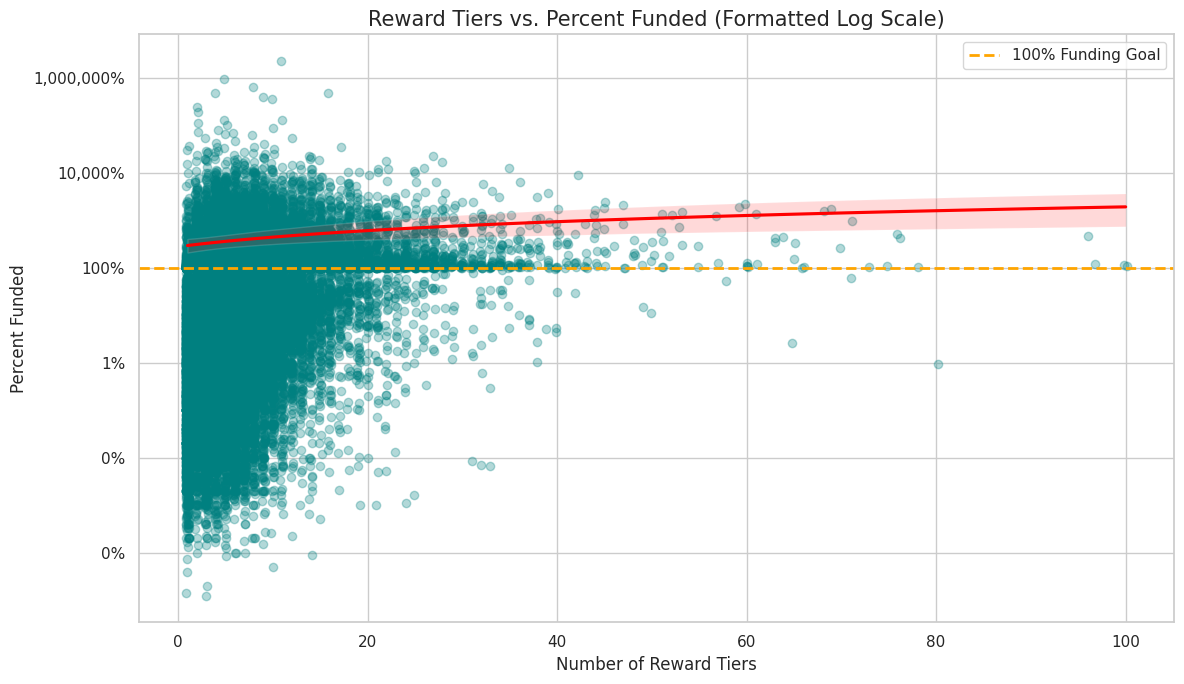

In [ ]:
# plot reward tiers vs percent funded with a regression line and log scale on the y-axis
plt.figure(figsize=(12, 7))

ax = sns.regplot(data=df, 
                 x='num_reward_tiers', 
                 y='percent_funded',
                 scatter_kws={'alpha':0.3, 'color':'teal'},
                 line_kws={'color':'red'},
                 x_jitter=0.2)

plt.yscale('log')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:,.0f}%'.format(y)))

plt.axhline(100, color='orange', linestyle='--', linewidth=2, label='100% Funding Goal')

plt.title('Reward Tiers vs. Percent Funded (Formatted Log Scale)', fontsize=15)
plt.xlabel('Number of Reward Tiers', fontsize=12)
plt.ylabel('Percent Funded', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# descriptive statistics of goal_converted_USD for successful and unsuccessful projects
# Subset where success == 1
pd.options.display.float_format = '{:,.2f}'.format
df_success = df[df['success'] == 1]
print(df_success['goal_converted_USD'].describe())

# Subset where success == 0
df_failure = df[df['success'] == 0]
print(df_failure['goal_converted_USD'].describe())


count      20,553.00
mean        8,161.36
std        20,954.52
min             0.65
25%         1,000.00
50%         3,176.25
75%         8,864.30
max     1,000,000.00
Name: goal_converted_USD, dtype: float64
count      19,748.00
mean       38,380.32
std       241,278.08
min             1.00
25%         2,500.00
50%         7,479.52
75%        22,123.19
max     9,168,991.36
Name: goal_converted_USD, dtype: float64


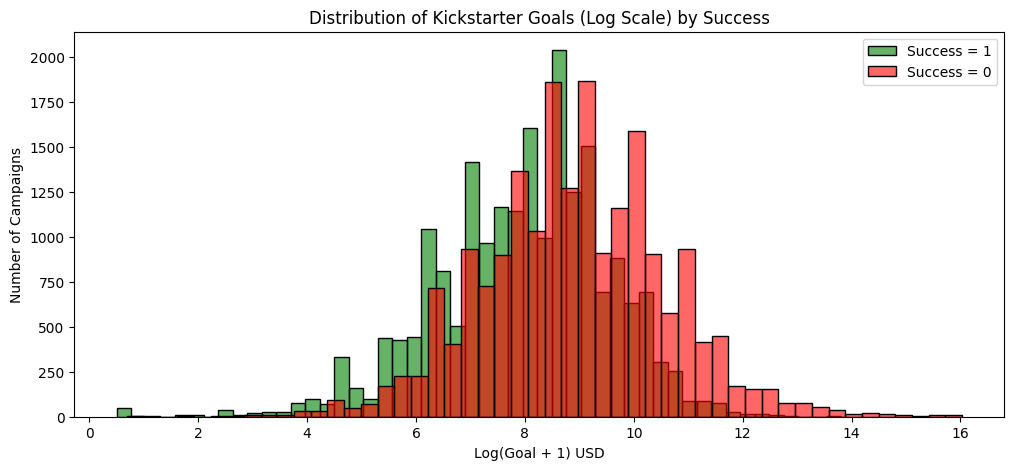

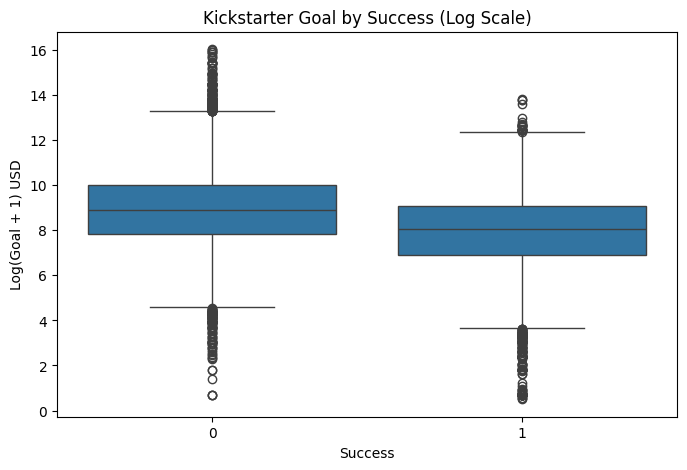

In [ ]:
# Histogram
plt.figure(figsize=(12,5))
sns.histplot(df_success['goal_converted_USD_log'], bins=50, color='green', label='Success = 1', alpha=0.6)
sns.histplot(df_failure['goal_converted_USD_log'], bins=50, color='red', label='Success = 0', alpha=0.6)
plt.xlabel('Log(Goal + 1) USD')
plt.ylabel('Number of Campaigns')
plt.title('Distribution of Kickstarter Goals (Log Scale) by Success')
plt.legend()
plt.show()

# Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x='success', y='goal_converted_USD_log', data=df)
plt.xlabel('Success')
plt.ylabel('Log(Goal + 1) USD')
plt.title('Kickstarter Goal by Success (Log Scale)')
plt.show()

In [ ]:
# Describe campaign duration for successful projects
print("campaign_duration for success = 1")
print(df_success['campaign_duration_days'].describe())

# Describe campaign duration for failed projects
print("campaign_duration for success = 0")
print(df_failure['campaign_duration_days'].describe())

=== campaign_duration for success = 1 ===
count   20,553
mean        31
std         11
min          1
25%         27
50%         30
75%         32
max        120
Name: campaign_duration_days, dtype: float64

=== campaign_duration for success = 0 ===
count   19,748
mean        36
std         14
min          1
25%         30
50%         30
75%         45
max         74
Name: campaign_duration_days, dtype: float64


In [ ]:
# Describe goal_converted_USD for successful and unsuccessful projects
# Describe for success = 1
print("Descriptive statistics for success = 1")
print(df_success.describe())

# Describe for success = 0
print("Descriptive statistics for success = 0")
print(df_failure.describe())

=== Descriptive statistics for success = 1 ===
       creator_backing_action_count       goal            id  profile_id  \
count                        20,553     20,553        20,553      20,553   
mean                              0     14,299 1,054,488,676   3,454,109   
std                               1    295,325   493,501,991   1,476,918   
min                               0          1        19,685         408   
25%                               0      1,000   876,321,521   2,428,607   
50%                               0      3,500 1,106,646,703   3,859,955   
75%                               0     10,000 1,245,374,627   4,736,252   
max                              41 40,000,000 2,147,453,784   5,225,921   

       profile_project_id  static_usd_rate     pledged  backers_count  \
count              20,553           20,553      20,553         20,553   
mean            3,454,109                1      60,311            203   
std             1,476,918                0     95

In [ ]:
# explore number of unique categorical variables
print("Unique location names:", df['location_name'].nunique())
print("Unique location states:", df['location_state'].nunique())
print("Unique location countries:", df['location_country'].nunique())
print("Unique location types:", df['location_type'].nunique())
print("Unique countries:", df['country'].nunique())
print("Unique currencies:", df['currency'].nunique())
print("Unique category names:", df['category_name'].nunique())
print("Unique category parent names:", df['category_parent_name'].nunique())

Unique location names: 5856
Unique location states: 734
Unique location countries: 154
Unique location types: 9
Unique countries: 25
Unique currencies: 15
Unique category names: 161
Unique category parent names: 15


In [31]:
# drop location_name and location_state
df = df.drop(columns=['location_name', 'location_state'], errors='ignore')

In [ ]:
# country represents the Kickstarter-supported countries where a project can legally be registered
# location_country is the physical location tagged by the creator

# feature called is_local (1 if country == location_country, 0 otherwise)
df['is_local'] = (df['country'].astype(str) == df['location_country'].astype(str)).astype(int)
print(df['is_local'].value_counts())

# drop location_country
df = df.drop(columns=['location_country'], errors='ignore')

is_local
1    38393
0     1908
Name: count, dtype: int64


In [33]:
# Group by parent, then find the variance of the sub-categories inside
parent_variance = df.groupby('category_parent_name')['category_name'].apply(
    lambda x: df.loc[x.index].groupby('category_name')['success'].mean().std()
)
print(parent_variance.sort_values(ascending=False))

category_parent_name
Fashion         0.355131
Games           0.322765
Photography     0.319560
Dance           0.288691
Music           0.281658
Film & Video    0.277364
Design          0.270839
Publishing      0.269611
Technology      0.265892
Art             0.236238
Food            0.234464
Comics          0.225085
Crafts          0.211687
Journalism      0.201167
Theater         0.176437
Name: category_name, dtype: float64


In [34]:
# check columns
print(df.columns)
print("Number of columns:", len(df.columns))

Index(['blurb', 'category_name', 'category_parent_name', 'country',
       'created_at', 'creator_has_admin_message_badge',
       'creator_ppo_has_action', 'creator_backing_action_count', 'currency',
       'deadline', 'disable_communication', 'goal', 'id', 'is_disliked',
       'is_liked', 'is_starrable', 'launched_at', 'location_type', 'name',
       'photo_1536x864', 'prelaunch_activated', 'profile_id',
       'profile_project_id', 'profile_show_feature_image',
       'profile_should_show_feature_image_section',
       'profile_feature_image_attributes_image_urls_default',
       'profile_feature_image_attributes_image_urls_baseball_card', 'slug',
       'source_url', 'staff_pick', 'static_usd_rate', 'urls_web_project',
       'urls_web_rewards', 'video', 'story_html', 'risks_html', 'rewards_html',
       'pledged', 'backers_count', 'usd_pledged', 'converted_pledged_amount',
       'profile_state', 'profile_state_changed_at', 'state_changed_at',
       'spotlight', 'percent_funded'

In [35]:
print(df['creator_ppo_has_action'].head())
print(df['creator_has_admin_message_badge'].head())
print(df['creator_ppo_has_action'].value_counts())
print(df['creator_has_admin_message_badge'].value_counts())

0    False
1    False
2    False
3    False
4    False
Name: creator_ppo_has_action, dtype: bool
0    False
1    False
2    False
3    False
4    False
Name: creator_has_admin_message_badge, dtype: bool
creator_ppo_has_action
False    39677
True       624
Name: count, dtype: int64
creator_has_admin_message_badge
False    40301
Name: count, dtype: int64


In [36]:
# check creator_backing_action_count
print(df['creator_backing_action_count'].describe())
print(df['creator_backing_action_count'].value_counts())

count    40301.000000
mean         0.024714
std          0.368195
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         41.000000
Name: creator_backing_action_count, dtype: float64
creator_backing_action_count
0.0     39677
1.0       489
2.0        78
3.0        23
4.0        10
5.0         7
6.0         4
8.0         2
9.0         2
11.0        2
7.0         2
10.0        1
13.0        1
41.0        1
35.0        1
14.0        1
Name: count, dtype: int64


In [37]:
# check disable_communication
print(df['disable_communication'].value_counts())
# zero variance feature

disable_communication
False    40301
Name: count, dtype: int64


In [38]:
print(df['prelaunch_activated'].value_counts())

prelaunch_activated
False    31081
True      9220
Name: count, dtype: int64


In [42]:
# remove data leakage columns
leakage_columns = [
    'pledged', 'backers_count', 'usd_pledged', 'converted_pledged_amount',
    'profile_state', 'profile_state_changed_at', 'state_changed_at', 'spotlight',
    'percent_funded', 'usd_pledge_per_backer',
    'is_liked', 'is_disliked', 'is_starrable',
    'staff_pick', 'state'
]
df = df.drop(columns=leakage_columns, errors='ignore')
print("Columns after removing data leakage ones:", df.columns.tolist())

Columns after removing data leakage ones: ['blurb', 'category_name', 'category_parent_name', 'country', 'creator_has_admin_message_badge', 'creator_ppo_has_action', 'creator_backing_action_count', 'currency', 'location_type', 'name', 'photo_1536x864', 'prelaunch_activated', 'video', 'campaign_duration_days', 'days_between_created_launched', 'launched_day', 'launched_day_of_week', 'launched_hour', 'launched_month', 'goal_converted_USD', 'goal_converted_USD_log', 'success', 'num_reward_tiers', 'lowest_pledge_level_usd', 'highest_pledge_level_usd', 'has_reward_images', 'average_number_of_words_per_reward', 'has_restricted_shipping', 'rewards_html_text', 'rewards_char_length', 'risks_html_text', 'risks_char_length', 'total_media_assets', 'num_static_images', 'num_animated_content', 'story_html_text', 'story_char_length', 'blurb_char_length', 'ratio_text_to_total_assets', 'total_text_length', 'is_local']


In [ ]:
# remove noise
noise_columns = [
    'profile_show_feature_image', 'profile_should_show_feature_image_section',
    'id', 'profile_id', 'profile_project_id', 'slug', 
    'urls_web_project', 'urls_web_rewards', 'source_url',
    'profile_feature_image_attributes_image_urls_default',
    'profile_feature_image_attributes_image_urls_baseball_card',
    'static_usd_rate',
    'disable_communication'
]

df = df.drop(columns=noise_columns, errors='ignore')
print("Columns after removing noise:", df.columns.tolist())

Columns after removing noise: ['blurb', 'category_name', 'category_parent_name', 'country', 'created_at', 'creator_has_admin_message_badge', 'creator_ppo_has_action', 'creator_backing_action_count', 'currency', 'deadline', 'goal', 'is_disliked', 'is_liked', 'is_starrable', 'launched_at', 'location_type', 'name', 'photo_1536x864', 'prelaunch_activated', 'staff_pick', 'video', 'story_html', 'risks_html', 'rewards_html', 'pledged', 'backers_count', 'usd_pledged', 'converted_pledged_amount', 'profile_state', 'profile_state_changed_at', 'state_changed_at', 'spotlight', 'percent_funded', 'state', 'campaign_duration_days', 'days_between_created_launched', 'launched_day', 'launched_day_of_week', 'launched_hour', 'launched_month', 'goal_converted_USD', 'goal_converted_USD_log', 'usd_pledge_per_backer', 'success', 'num_reward_tiers', 'lowest_pledge_level_usd', 'highest_pledge_level_usd', 'has_reward_images', 'average_number_of_words_per_reward', 'has_restricted_shipping', 'rewards_html_text', 'r

In [ ]:
# redundant columns
redundant_columns = [
    'goal', 
    'created_at', 'launched_at', 'deadline',
    'story_html', 'risks_html', 'rewards_html',
    'is_english_project'
]
df = df.drop(columns=redundant_columns, errors='ignore')

In [ ]:
# columns after cleaning
print(df.columns)
print("Number of columns after cleaning:", len(df.columns))

Index(['blurb', 'category_name', 'category_parent_name', 'country',
       'creator_has_admin_message_badge', 'creator_ppo_has_action',
       'creator_backing_action_count', 'currency', 'location_type', 'name',
       'photo_1536x864', 'prelaunch_activated', 'video',
       'campaign_duration_days', 'days_between_created_launched',
       'launched_day', 'launched_day_of_week', 'launched_hour',
       'launched_month', 'goal_converted_USD', 'goal_converted_USD_log',
       'success', 'num_reward_tiers', 'lowest_pledge_level_usd',
       'highest_pledge_level_usd', 'has_reward_images',
       'average_number_of_words_per_reward', 'has_restricted_shipping',
       'rewards_html_text', 'rewards_char_length', 'risks_html_text',
       'risks_char_length', 'total_media_assets', 'num_static_images',
       'num_animated_content', 'story_html_text', 'story_char_length',
       'blurb_char_length', 'ratio_text_to_total_assets', 'total_text_length',
       'is_local'],
      dtype='str')
Numbe

In [44]:
# save to new csv
df.to_csv('final_dataset_cleaned.csv', index=False)